# 02 · Preprocessing (Phase 2) — ds004752 verbal working memory sEEG

**Pipeline:** EDF → bipolar re-reference (adjacent contacts on one shaft) → 16 × 0.5 s bins × 5 band powers per trial → per-channel z-score (clean trials) → region tensors `X_region.npy` `(trials, 4 regions, 16 bins, 5 bands)`.

**Decisions baked in (from the Phase 2 checks)**
- **Units:** MNE reads these EDFs with unit `n/a` and returns values already in µV, so there is **no** `* 1e6`. An assertion checks the scale.
- **Reference:** `iEEGReference = common intracranial reference`, so I use bipolar re-referencing. Pairs spanning two different labeled regions are tagged `mixed` and excluded from region averages.
- **Sampling rates:** sub-01–10 are 2000 Hz, sub-11–15 are 4000/4096 Hz. The bin is `fs/2` samples, so every subject has 2 Hz resolution.
- **Header bug:** sub-06 ses-04 has an invalid EDF start time, patched in a temporary copy.
- **Epoch timing (README):** encoding 2 s → maintenance 3 s → probe/recall to 8 s, so windows are 0–2, 2–5 and 5–8 s. `events.tsv` has no boundaries; this assumes each 8 s epoch starts at encoding onset (checked by the plots below).
- **Region averages** need ≥ 2 usable bipolar channels, otherwise the region is `NaN`.

**Setup:** add the `ds004752-ieeg` dataset as input. Internet is needed once for `pip install mne` (or mne must already be installed). Run top to bottom; the full run takes about 4–8 min. Outputs were cleared on purpose, because the old ones came from the monopolar pipeline.

In [1]:
import pathlib

edfs = sorted(pathlib.Path("/kaggle/input").rglob("*_ieeg.edf"))
sizes = [p.stat().st_size for p in edfs]
print("EDF files:", len(edfs), "(expect 68)")
print("Total GB on disk:", round(sum(sizes) / 1e9, 2), "(expect ~8.8)")
print("Tiny files:", sum(s < 10_000_000 for s in sizes))
print("Subjects:", sorted({p.parts[-4] for p in edfs}))
print("Example path:", edfs[0] if edfs else None)

EDF files: 68 (expect 68)
Total GB on disk: 8.84 (expect ~8.8)
Tiny files: 0
Subjects: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-15']
Example path: /kaggle/input/datasets/rachana240906/ds004752-ieeg/data/ds004752/sub-01/ses-01/ieeg/sub-01_ses-01_task-verbalWM_run-01_ieeg.edf


In [2]:
try:
    import mne
except ImportError:
    !pip install -q mne
    import mne
print("mne", mne.__version__)

mne 1.13.2


In [3]:
import os, re, json, shutil, warnings, pathlib
import numpy as np, pandas as pd
import mne, scipy.signal as sps
from scipy import stats
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# --- paths -------------------------------------------------------------
DATA = pathlib.Path("/kaggle/input/datasets/rachana240906/ds004752-ieeg/data/ds004752")
if not DATA.exists():                                  # fallback: locate via the EDFs themselves
    _edf = next(pathlib.Path("/kaggle/input").rglob("*_ieeg.edf"), None)
    assert _edf is not None, "No EDF files under /kaggle/input - the dataset is not attached to this notebook (Add Input)"
    DATA = _edf.parents[3]                             # .../sub-XX/ses-XX/ieeg/file.edf -> folder containing sub-XX
CACHE = pathlib.Path("/kaggle/working/cache_bip"); CACHE.mkdir(exist_ok=True)   # per-session, per-pair features
META  = pathlib.Path("/kaggle/working/meta");      META.mkdir(exist_ok=True)
OUT   = pathlib.Path("/kaggle/working/phase2_out"); OUT.mkdir(exist_ok=True)    # final deliverables for Phase 3
print("DATA:", DATA)
print(len(list(DATA.glob("sub-*/ses-*/ieeg/*_ieeg.edf"))), "EDF files (expect 68)")

# --- feature config ----------------------------------------------------
BANDS = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "lgamma": (30, 70), "hgamma": (70, 150)}
LINE  = [(48, 52), (98, 102), (148, 152)]              # 50 Hz mains + harmonics
NBIN  = 16                                             # 16 bins x 0.5 s = 8 s
BIN_S = 0.5
T_BINS = np.arange(NBIN) * BIN_S + BIN_S / 2           # bin centres (s)

# epoch windows from the dataset README (encoding 2 s, maintenance 3 s, probe/recall afterwards)
EPOCH = {"encoding": (0, 2), "maintenance": (2, 5), "probe/recall": (5, 8)}
def win_bins(name):
    lo, hi = EPOCH[name]
    return slice(int(lo / BIN_S), int(hi / BIN_S))

CORE = ["hippocampus", "amygdala", "parahippocampal", "lateral_temporal"]
MIN_CH = 2                                             # min usable bipolar channels for a region mean

DATA: /kaggle/input/datasets/rachana240906/ds004752-ieeg/data/ds004752
68 EDF files (expect 68)


In [4]:
def stack(pattern):
    rows = []
    for f in sorted(DATA.glob(pattern)):
        d = pd.read_csv(f, sep="\t")
        d["subject"], d["session"] = f.parts[-4], f.parts[-3]
        rows.append(d)
    return pd.concat(rows, ignore_index=True)

GROUPS = {"hippocampus": ["Hipp"], "amygdala": ["Amyg"], "parahippocampal": ["PhG"],
          "lateral_temporal": ["STG", "MTG", "ITG", "pSTS"], "unlabeled": ["no_label_found", "nan"]}
G2R = {g: r for r, gs in GROUPS.items() for g in gs}

el = stack("sub-*/ses-*/ieeg/*_electrodes.tsv")
el["AnatomicalLocation"] = el["AnatomicalLocation"].astype(str)
el["gyrus"]  = el.AnatomicalLocation.str.split(",").str[0].str.strip()
el["region"] = el.gyrus.map(G2R).fillna("other_labeled")
el.to_csv(META / "electrodes_all.csv", index=False)

ev = stack("sub-*/ses-*/ieeg/*_events.tsv")
ev["clean"] = ((ev.SetSize > 0) & (ev.Artifact == 0)).astype(int)
ev.to_csv(META / "trials_all.csv", index=False)
print("Clean trials:", int(ev.clean.sum()), "of", len(ev), "(expect 3185 of 3353)")

Clean trials: 3185 of 3353 (expect 3185 of 3353)


In [5]:
def band_power(x, fs):
    "x: (..., fs/2 samples) -> (..., 5) log10 band power (uV^2/Hz); line-noise bands removed."
    f, p = sps.welch(x, fs=fs, nperseg=int(fs * BIN_S), detrend="constant", axis=-1)
    keep = np.ones_like(f, bool)
    for lo, hi in LINE:
        keep &= ~((f >= lo) & (f <= hi))
    out = [np.log10(p[..., keep & (f >= lo) & (f < hi)].mean(-1) + 1e-12) for lo, hi in BANDS.values()]
    return np.stack(out, -1)

def read_edf_safe(edf):
    try:
        return mne.io.read_raw_edf(edf, preload=True, verbose="ERROR")
    except ValueError as e:
        if "second must be" not in str(e):
            raise
        tmp = pathlib.Path("/kaggle/working/_tmp_fixed.edf")      # sub-06 ses-04: invalid start-time header
        shutil.copyfile(edf, tmp)
        with open(tmp, "r+b") as f:                                # EDF header: start time = bytes 176-184 "hh.mm.ss"
            f.seek(176); hhmm = f.read(8).decode("ascii")[:6]
            f.seek(176); f.write((hhmm + "00").encode("ascii"))
        raw = mne.io.read_raw_edf(tmp, preload=True, verbose="ERROR")
        tmp.unlink()
        return raw

def bipolar_pairs(names):
    "adjacent contacts on the same shaft: (prefix, n) with (prefix, n+1)"
    idx = {}
    for i, n in enumerate(names):
        m = re.match(r"^(.*?)(\d+)$", n)
        if m:
            idx[(m.group(1), int(m.group(2)))] = i
    return [(i, idx[(p, k + 1)]) for (p, k), i in sorted(idx.items()) if (p, k + 1) in idx]

def pair_region(ra, rb):
    if ra == rb: return ra
    if ra == "unlabeled": return rb
    if rb == "unlabeled": return ra
    return "mixed"

def process_session(edf):
    base = str(edf).replace("_ieeg.edf", "")
    sub, ses = edf.parts[-4], edf.parts[-3]
    evs = pd.read_csv(base + "_events.tsv", sep="\t")
    chs = pd.read_csv(base + "_channels.tsv", sep="\t")
    els = pd.read_csv(base + "_electrodes.tsv", sep="\t")

    raw = read_edf_safe(edf)
    assert raw.ch_names == chs.name.tolist(), "channel mismatch"
    fs = int(round(raw.info["sfreq"])); bin_ = fs // 2
    X = raw.get_data()                                   # already in uV (EDF unit 'n/a', no scaling applied)
    assert 1 < np.median(X.std(1)) < 1000, ("unexpected scale", sub, ses, np.median(X.std(1)))
    assert evs.endSample.max() <= X.shape[1]

    names = [n if t == "SEEG" else "" for n, t in zip(chs.name, chs.type)]
    pairs = bipolar_pairs(names)
    assert pairs, (sub, ses, "no bipolar pairs")
    ia, ib = np.array(pairs).T
    cn = chs.name.values
    pair_names = [f"{cn[a]}-{cn[b]}" for a, b in pairs]

    T, P = len(evs), len(pairs)
    tc  = np.zeros((T, P, NBIN, len(BANDS)), np.float32)
    var = np.zeros((T, P))
    for i, (b, e) in enumerate(zip(evs.begSample, evs.endSample)):
        seg = X[ia, b - 1:e] - X[ib, b - 1:e]            # bipolar
        assert seg.shape[-1] == 8 * fs, (sub, ses, seg.shape, fs)
        var[i] = seg.var(-1)
        tc[i] = band_power(seg.reshape(P, NBIN, bin_), fs)

    lv = np.log10(var + 1e-12).mean(0)
    z = (lv - np.median(lv)) / (1.4826 * np.median(np.abs(lv - np.median(lv))) + 1e-9)
    bad = (np.abs(z) > 4) | (var.mean(0) < 1e-3)         # 1e-3 uV^2: below EDF quantization noise

    g = els.AnatomicalLocation.astype(str).str.split(",").str[0].str.strip().map(G2R).fillna("other_labeled")
    reg = dict(zip(els.name, g))
    mono = [reg.get(n, "unlabeled") for n in chs.name]
    region = np.array([pair_region(mono[a], mono[b]) for a, b in pairs], dtype=str)

    np.savez_compressed(CACHE / f"{sub}_{ses}.npz", tc=tc, bad=bad, region=region,
                        ch=np.array(pair_names, dtype=str), nTrial=evs.nTrial.values, fs=fs)
    return sub, ses, T, P, int(bad.sum()), fs

In [6]:
# quick test: a 2000 Hz session, a 4096 Hz session, and the session with the broken EDF header
edfs = sorted(DATA.glob("sub-*/ses-*/ieeg/*_ieeg.edf"))
pick = lambda s: next(p for p in edfs if f"/{s}/" in str(p))
for s in ["sub-01/ses-01", "sub-13/ses-01", "sub-06/ses-04"]:
    print(process_session(pick(s)))
d = np.load(CACHE / "sub-01_ses-01.npz")
print({k: d[k].shape for k in d.files})
print("mean log10 power per band (expect roughly -1..3):", d["tc"][:, ~d["bad"]].mean((0, 1, 2)).round(2))

('sub-01', 'ses-01', 50, 42, 0, 2000)
('sub-13', 'ses-01', 50, 49, 0, 4096)
('sub-06', 'ses-04', 50, 56, 0, 2000)
{'tc': (50, 42, 16, 5), 'bad': (42,), 'region': (42,), 'ch': (42,), 'nTrial': (50,), 'fs': ()}
mean log10 power per band (expect roughly -1..3): [ 1.15  0.67  0.1  -0.72 -1.66]


In [7]:
log, failed = [], []
for edf in tqdm(edfs):
    try:
        log.append(process_session(edf))
    except Exception as e:
        failed.append((edf.parts[-4], edf.parts[-3], repr(e)[:150]))
        print("FAILED", edf.parts[-4], edf.parts[-3], repr(e)[:150])
log = pd.DataFrame(log, columns=["subject", "session", "n_trials", "n_ch", "n_bad", "fs"])
log.to_csv(META / "preprocess_log.csv", index=False)
print(len(log), "sessions (expect 68) | trials:", log.n_trials.sum(), "(expect 3353) | bad pairs:", log.n_bad.sum(), "| failed:", len(failed))
print(log.groupby("subject")[["n_ch", "n_bad", "fs"]].max().T.to_string())      # n_ch = bipolar pairs

  0%|          | 0/68 [00:00<?, ?it/s]

68 sessions (expect 68) | trials: 3353 (expect 3353) | bad pairs: 6 | failed: 0
subject  sub-01  sub-02  sub-03  sub-04  sub-05  sub-06  sub-07  sub-08  sub-09  sub-10  sub-11  sub-12  sub-13  sub-14  sub-15
n_ch         42      56      35      56      28      56      56      53      56      14      21      35      49      56      56
n_bad         0       0       0       0       0       0       0       0       0       0       0       0       0       0       4
fs         2000    2000    2000    2000    2000    2000    2000    2000    2000    2000    4000    4000    4096    4000    4096


## QC: absolute power levels and bad-pair diagnostics

In [8]:
rows, brow = [], []
for npz in sorted(CACHE.glob("sub-*_ses-*.npz")):
    d = np.load(npz); sub = npz.stem.split("_")[0]
    tc, bad, reg = d["tc"], d["bad"], d["region"]
    ok = ~bad
    rows.append([sub, int(d["fs"]), *tc[:, ok].mean((0, 1, 2)), int(bad.sum()), len(bad)])
    lvl = tc.mean((0, 2, 3)); med = np.median(lvl[ok])
    brow += [(sub, r, bool(b), l - med) for r, b, l in zip(reg, bad, lvl)]

df = pd.DataFrame(rows, columns=["sub", "fs", *BANDS, "n_bad", "n_pairs"])
print("Mean log10 power per band (should be ~ -1..3, no step between 2000 Hz and 4000 Hz subjects):")
print(df.groupby(["sub", "fs"]).mean().round(2).to_string())

bd = pd.DataFrame(brow, columns=["sub", "region", "bad", "lvl"])
print("\nBad pairs by region:");  print(bd.groupby("region").bad.agg(["mean", "sum", "size"]).round(3))
print("\nBad-pair rate, sub-13 / sub-15:")
print(bd[bd["sub"].isin(["sub-13", "sub-15"])].groupby(["sub", "region"]).bad.mean().unstack().round(2))
print("\nFraction of bad pairs with above-median power (1 = artifact-like, 0 = quiet contacts):",
      round((bd[bd.bad].lvl > 0).mean(), 2))
for s in ["sub-13", "sub-15"]:
    for npz in sorted(CACHE.glob(f"{s}_ses-0[12].npz")):
        d = np.load(npz); print(npz.stem, "bad:", d["ch"][d["bad"]].tolist())

Mean log10 power per band (should be ~ -1..3, no step between 2000 Hz and 4000 Hz subjects):
             theta  alpha  beta  lgamma  hgamma  n_bad  n_pairs
sub    fs                                                      
sub-01 2000   1.53   0.92  0.24   -0.61   -1.54    0.0     42.0
sub-02 2000   1.50   0.87  0.13   -0.81   -1.70    0.0     56.0
sub-03 2000   1.23   0.90  0.18   -0.75   -1.71    0.0     35.0
sub-04 2000   1.58   1.06  0.21   -0.94   -1.77    0.0     56.0
sub-05 2000   1.55   1.18  0.45   -0.46   -1.47    0.0     28.0
sub-06 2000   1.40   0.91  0.15   -0.99   -1.86    0.0     56.0
sub-07 2000   1.16   0.88  0.10   -0.90   -1.84    0.0     56.0
sub-08 2000   0.97   0.63  0.17   -0.75   -1.58    0.0     53.0
sub-09 2000   1.47   0.78 -0.07   -1.01   -1.88    0.0     56.0
sub-10 2000   1.39   0.93  0.43   -0.61   -1.61    0.0     14.0
sub-11 4000   1.74   1.00  0.23   -0.51   -1.44    0.0     21.0
sub-12 4000   1.53   1.08  0.43   -0.58   -1.52    0.0     35.0
sub-13 4096

In [9]:
# epoch-timing facts from the dataset itself
base = str(edfs[0]).replace("_ieeg.edf", "")
j = json.load(open(base + "_ieeg.json"))
print("Reference:", j["iEEGReference"], "| EpochLength:", j["EpochLength"], "s")
print("Task:", j["TaskDescription"])
print("Assumed windows (s):", EPOCH)
rt = ev.ResponseTime
print("\nResponseTime (s) summary:\n", rt.describe().round(3).to_string())
print("RT <= 0:", int((rt <= 0).sum()), "| RT > 3 s (cannot fit in 8 s epoch if probe starts at 5 s):", int((rt > 3).sum()))

Reference: common intracranial reference | EpochLength: 8 s
Task: In the task, sets of consonants are presented and have to be memorized. The set size (4, 6, or 8 letters) determines working memory workload. In each trial, presentation of a letter string (encoding period, 2 s) is followed by a delay (maintenance period, 3 s). After the delay, a probe letter is presented. Participants indicate whether the probe was in the letter string or not.
Assumed windows (s): {'encoding': (0, 2), 'maintenance': (2, 5), 'probe/recall': (5, 8)}

ResponseTime (s) summary:
 count    3353.000
mean        1.327
std         0.655
min         0.000
25%         0.957
50%         1.142
75%         1.454
max         9.973
RT <= 0: 17 | RT > 3 s (cannot fit in 8 s epoch if probe starts at 5 s): 93


## 2.2–2.4 Normalize and build region tensors

In [10]:
meta = pd.read_csv(META / "trials_all.csv")

Xs, Ms, cov = [], [], []
for npz in sorted(CACHE.glob("sub-*_ses-*.npz")):
    sub, ses = npz.stem.split("_")
    d = np.load(npz)
    tc, bad, region = d["tc"], d["bad"], d["region"]
    m = meta[(meta.subject == sub) & (meta.session == ses)].reset_index(drop=True)
    assert len(m) == len(tc) and (m.nTrial.values == d["nTrial"]).all(), (sub, ses)
    m["fs"] = int(d["fs"])

    clean = m.clean.values.astype(bool)
    mu = tc[clean].mean((0, 2), keepdims=True)                 # per pair & band, over clean trials and time bins
    sd = tc[clean].std((0, 2), keepdims=True) + 1e-6
    z = (tc - mu) / sd

    reg = np.full((len(tc), len(CORE), NBIN, len(BANDS)), np.nan, np.float32)
    n_ch = []
    for k, r in enumerate(CORE):
        sel = (region == r) & ~bad
        n_ch.append(int(sel.sum()))
        if sel.sum() >= MIN_CH:                                # one channel is too noisy for a region average
            reg[:, k] = z[:, sel].mean(1)
    Xs.append(reg); Ms.append(m)
    cov.append([sub, ses, *n_ch])

X = np.concatenate(Xs); M = pd.concat(Ms, ignore_index=True)   # row i of M describes X[i]
cov = pd.DataFrame(cov, columns=["subject", "session", *CORE])
assert len(X) == len(M) == 3353
print(X.shape, "| NaN fraction per region", CORE, np.isnan(X).all((2, 3)).mean(0).round(2))

print("\nUsable bipolar pairs per subject (max over sessions):")
print(cov.groupby("subject")[CORE].max().T.to_string())
has = cov.groupby("subject")[CORE].max() >= MIN_CH
print(f"\nSubjects with >= {MIN_CH} usable pairs per region (Phase 1.4 decision input):")
print(has.sum().to_string(), "| subjects with all 4 regions:", int(has.all(1).sum()),
      "| hippocampus + lateral_temporal:", int((has.hippocampus & has.lateral_temporal).sum()))

(3353, 4, 16, 5) | NaN fraction per region ['hippocampus', 'amygdala', 'parahippocampal', 'lateral_temporal'] [0.28 0.45 0.45 0.  ]

Usable bipolar pairs per subject (max over sessions):
subject           sub-01  sub-02  sub-03  sub-04  sub-05  sub-06  sub-07  sub-08  sub-09  sub-10  sub-11  sub-12  sub-13  sub-14  sub-15
hippocampus            4       1       5       6       5      10      12       4      11       4       1       4       0       8       4
amygdala               6       3       2       4       0       4       6       3       2       0       0       0       0       1       7
parahippocampal        0       3       1       3       0       1       2       3       2       0       0       0       6       2       2
lateral_temporal      21      29      12      27      12      23      25      31      22       8      13      18      22      27      26

Subjects with >= 2 usable pairs per region (Phase 1.4 decision input):
hippocampus         12
amygdala             9
parahippoc

## 2.5 Sanity plots (windows shaded: encoding / maintenance / probe-recall)

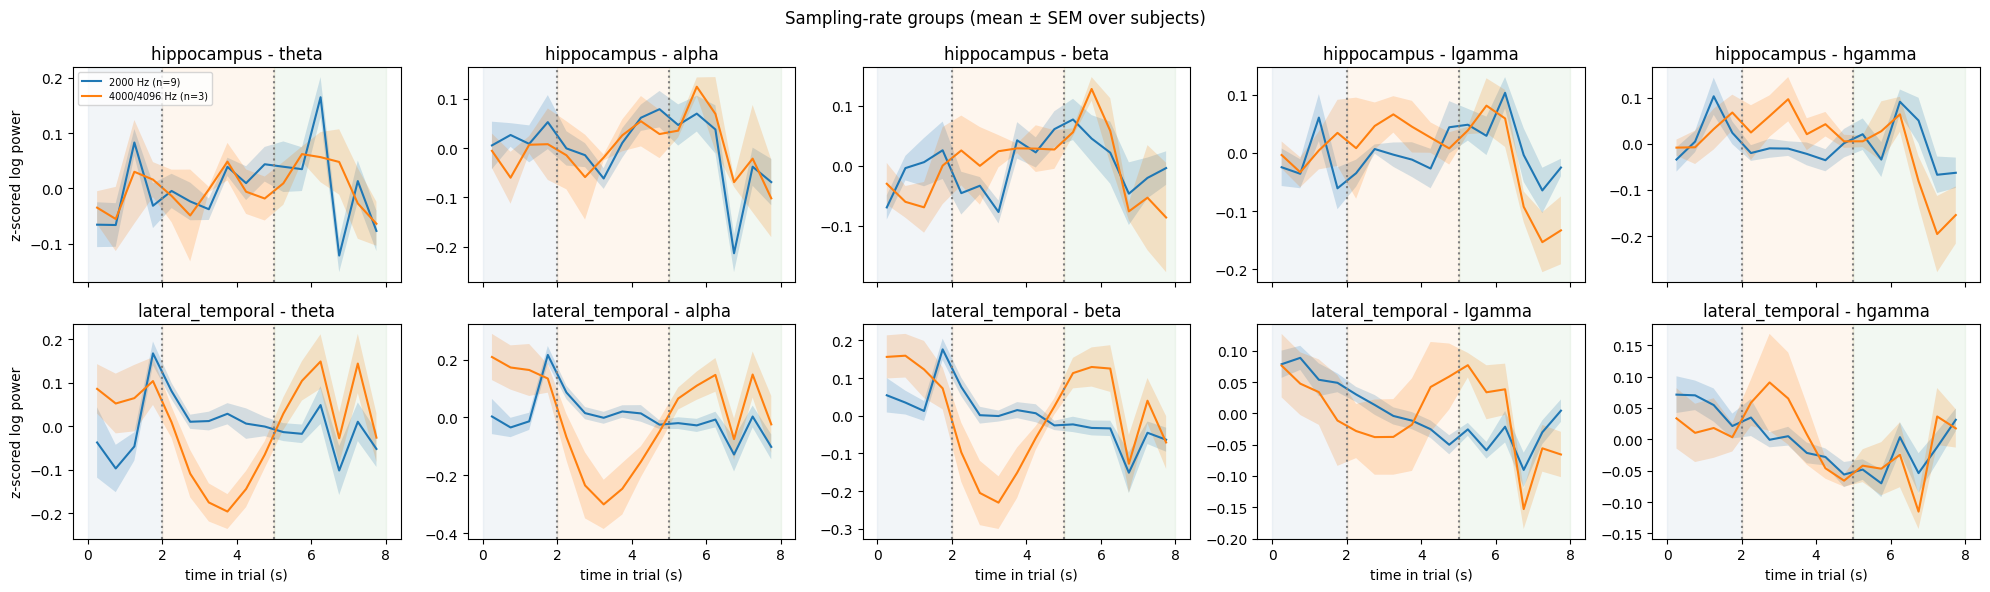

In [11]:
WCOL = ["#4C78A8", "#F58518", "#54A24B"]
def mark_windows(ax):
    for (lo, hi), c in zip(EPOCH.values(), WCOL):
        ax.axvspan(lo, hi, color=c, alpha=0.07)
    for x in (2, 5): ax.axvline(x, color="gray", ls=":")

def subj_curves(sel, k, b):
    "per-subject mean time course (subjects equally weighted) -> (n_subj, NBIN)"
    out = []
    for _, g in M[sel].groupby("subject"):
        v = X[g.index.values, k, :, b]
        if not np.isnan(v).all():
            out.append(np.nanmean(v, 0))
    return np.array(out)

def band_ax(ax, curves, label):
    if len(curves) == 0: return
    mu = curves.mean(0)
    se = curves.std(0, ddof=1) / np.sqrt(len(curves)) if len(curves) > 1 else np.zeros(NBIN)
    ax.plot(T_BINS, mu, label=f"{label} (n={len(curves)})")
    ax.fill_between(T_BINS, mu - se, mu + se, alpha=0.2)

C = M.clean == 1
# (1) sampling-rate check: the two groups should agree in shape after per-channel z-scoring
fig, axs = plt.subplots(2, 5, figsize=(20, 6), sharex=True)
for i, r in enumerate(["hippocampus", "lateral_temporal"]):
    k = CORE.index(r)
    for b, name in enumerate(BANDS):
        band_ax(axs[i, b], subj_curves(C & (M.fs == 2000), k, b), "2000 Hz")
        band_ax(axs[i, b], subj_curves(C & (M.fs != 2000), k, b), "4000/4096 Hz")
        mark_windows(axs[i, b]); axs[i, b].set_title(f"{r} - {name}")
    axs[i, 0].set_ylabel("z-scored log power")
axs[0, 0].legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel("time in trial (s)")
fig.suptitle("Sampling-rate groups (mean ± SEM over subjects)"); plt.tight_layout(); plt.show()

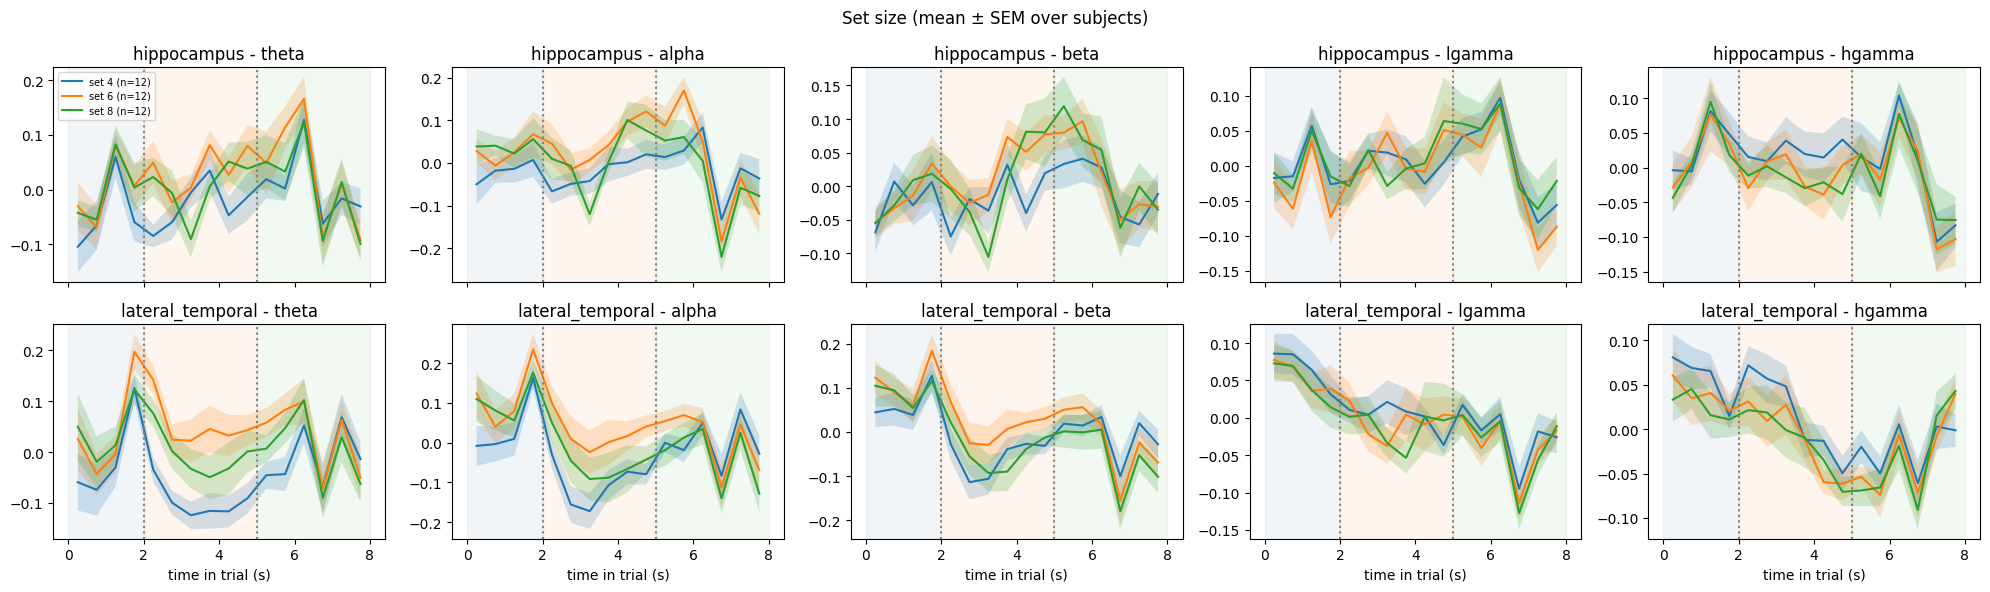

In [12]:
# (2) set-size effect
sizes = sorted(M.SetSize[C].unique())
fig, axs = plt.subplots(2, 5, figsize=(20, 6), sharex=True)
for i, r in enumerate(["hippocampus", "lateral_temporal"]):
    k = CORE.index(r)
    for b, name in enumerate(BANDS):
        for s in sizes:
            band_ax(axs[i, b], subj_curves(C & (M.SetSize == s), k, b), f"set {s}")
        mark_windows(axs[i, b]); axs[i, b].set_title(f"{r} - {name}")
axs[0, 0].legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel("time in trial (s)")
fig.suptitle("Set size (mean ± SEM over subjects)"); plt.tight_layout(); plt.show()

In [13]:
# (3) paired test: does maintenance-window power change with set size?
# Per subject: slope of mean maintenance power vs set size; then one-sample tests across subjects. Holm over all region x band tests.
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, j in enumerate(o):
        run = max(run, (m - i) * p[j]); adj[j] = min(1.0, run)
    return adj

mb = win_bins("maintenance")
Mc = M[C]
rows = []
for ri, r in enumerate(CORE):
    for bi, bname in enumerate(BANDS):
        slopes = []
        for _, g in Mc.groupby("subject"):
            xs, ys = [], []
            for s, gs in g.groupby("SetSize"):
                v = X[gs.index.values][:, ri, :, bi][:, mb].mean(1)
                v = v[~np.isnan(v)]
                if len(v): xs.append(s); ys.append(v.mean())
            if len(xs) >= 3: slopes.append(np.polyfit(xs, ys, 1)[0])
        slopes = np.array(slopes)
        if len(slopes) < 4: continue
        t_, p_t = stats.ttest_1samp(slopes, 0)
        try: p_w = stats.wilcoxon(slopes).pvalue
        except ValueError: p_w = np.nan
        rows.append([r, bname, len(slopes), slopes.mean(), t_, p_t, p_w])
res = pd.DataFrame(rows, columns=["region", "band", "n_subj", "mean_slope_per_item", "t", "p_ttest", "p_wilcoxon"])
res["p_holm"] = holm(res.p_ttest.values)
print("Slope > 0 = more maintenance power with higher load. Holm over", len(res), "tests.")
print(res.sort_values("p_ttest").round(4).to_string(index=False))
res.to_csv(OUT / "setsize_maintenance_tests.csv", index=False)

Slope > 0 = more maintenance power with higher load. Holm over 20 tests.
          region   band  n_subj  mean_slope_per_item       t  p_ttest  p_wilcoxon  p_holm
lateral_temporal  theta      15               0.0227  2.5599   0.0227      0.0479  0.4535
        amygdala  theta       9               0.0200  2.7542   0.0249      0.0273  0.4731
 parahippocampal  theta       8               0.0179  1.7415   0.1251      0.0547  1.0000
     hippocampus hgamma      12              -0.0104 -1.6156   0.1345      0.1294  1.0000
lateral_temporal  alpha      15               0.0139  1.5628   0.1404      0.2078  1.0000
lateral_temporal hgamma      15              -0.0074 -1.4577   0.1670      0.0833  1.0000
lateral_temporal lgamma      15              -0.0039 -0.9476   0.3594      0.1514  1.0000
     hippocampus  alpha      12               0.0084  0.9117   0.3814      0.3804  1.0000
     hippocampus   beta      12               0.0059  0.9105   0.3821      0.3394  1.0000
        amygdala  alpha    

trials used: 3102 of 3185


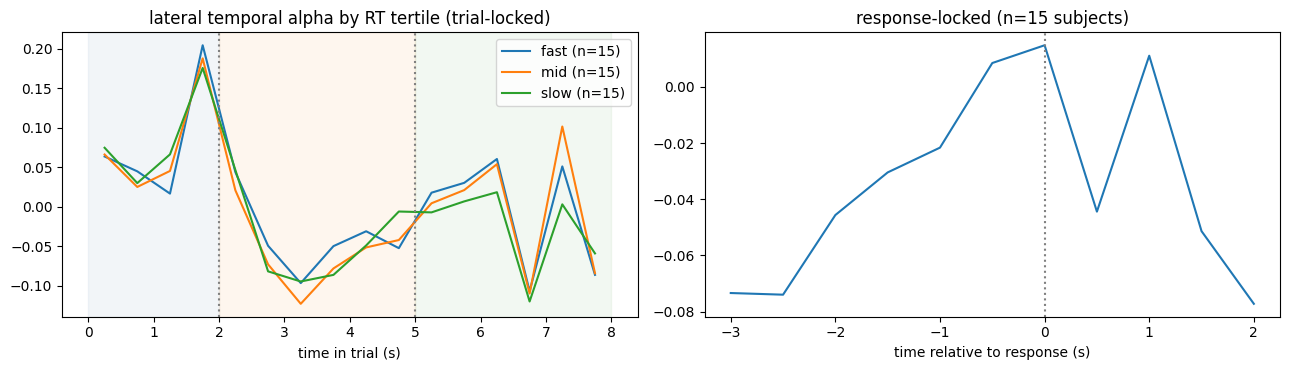

In [14]:
# (4) is the dip near 7-7.5 s trial-locked or response-locked?  Assumes RT is measured from probe onset (5 s) - check against the plot.
c = M[C & (M.ResponseTime > 0) & (M.ResponseTime < 3)].copy()
print("trials used:", len(c), "of", int(C.sum()))
c["rt_grp"] = pd.cut(c.groupby("subject").ResponseTime.rank(pct=True), [0, 1/3, 2/3, 1], labels=["fast", "mid", "slow"])

k, b = CORE.index("lateral_temporal"), list(BANDS).index("alpha")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for gname in ["fast", "mid", "slow"]:
    v = []
    for _, d in c[c.rt_grp == gname].groupby("subject"):
        x = X[d.index.values, k, :, b]
        if not np.isnan(x).all(): v.append(np.nanmean(x, 0))
    axs[0].plot(T_BINS, np.mean(v, 0), label=f"{gname} (n={len(v)})")
mark_windows(axs[0]); axs[0].legend(); axs[0].set_xlabel("time in trial (s)"); axs[0].set_title("lateral temporal alpha by RT tertile (trial-locked)")

REL = np.arange(-6, 6)                                   # bins relative to the response bin
per_sub = []
for _, g in c.groupby("subject"):
    acc = []
    for i, rt in zip(g.index.values, g.ResponseTime.values):
        idx = int((5 + rt) / BIN_S) + REL
        ok = (idx >= 0) & (idx < NBIN)
        v = np.full(len(REL), np.nan); v[ok] = X[i, k, idx[ok], b]
        acc.append(v)
    acc = np.array(acc)
    if not np.isnan(acc).all():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            per_sub.append(np.nanmean(acc, 0))
per_sub = np.array(per_sub)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    resp_mean = np.nanmean(per_sub, 0)                   # bins past the 8 s epoch end are NaN
axs[1].plot(REL * BIN_S, resp_mean); axs[1].axvline(0, color="gray", ls=":")
axs[1].set_xlabel("time relative to response (s)"); axs[1].set_title(f"response-locked (n={len(per_sub)} subjects)")
plt.tight_layout(); plt.show()

## Persist (Save Version afterwards) and final checks

In [15]:
np.save(OUT / "X_region.npy", X)                         # (3353, 4, 16, 5)
M.to_csv(OUT / "M_region.csv", index=False)              # row i of M describes X[i]
cov.to_csv(OUT / "region_coverage_sessions.csv", index=False)
log.to_csv(OUT / "preprocess_log.csv", index=False)
for f in ["electrodes_all.csv", "trials_all.csv"]:
    shutil.copy(META / f, OUT / f)

# --- Phase 2 checklist ---------------------------------------------------
checks = {
    "68 sessions processed, none failed":      len(log) == 68 and not failed,
    "3353 trials, X aligned with M":           X.shape == (3353, 4, 16, 5) and len(M) == 3353,
    "bipolar log-power in plausible range":    bool(df[list(BANDS)].values.min() > -4 and df[list(BANDS)].values.max() < 6),
    "z-scored features finite where present":  bool(np.isfinite(X[~np.isnan(X)]).all()),
    "lateral_temporal present in >=99% of trials":  bool((~np.isnan(X[:, CORE.index("lateral_temporal")]).all(axis=(1, 2))).mean() > 0.99),
}
for k_, v_ in checks.items(): print("PASS" if v_ else "CHECK", "-", k_)
print()
for p in sorted(OUT.iterdir()): print(f"{p.name:34s} {p.stat().st_size/1e6:8.2f} MB")
print("\nNext: Save Version, then add /kaggle/working/phase2_out as a dataset (or as notebook output) for 03_encoder.")

PASS - 68 sessions processed, none failed
PASS - 3353 trials, X aligned with M
PASS - bipolar log-power in plausible range
PASS - z-scored features finite where present
PASS - lateral_temporal present in >=99% of trials

M_region.csv                           0.23 MB
X_region.npy                           4.29 MB
electrodes_all.csv                     0.55 MB
preprocess_log.csv                     0.00 MB
region_coverage_sessions.csv           0.00 MB
setsize_maintenance_tests.csv          0.00 MB
trials_all.csv                         0.22 MB

Next: Save Version, then add /kaggle/working/phase2_out as a dataset (or as notebook output) for 03_encoder.


In [16]:
!ls /kaggle/input
!ls /kaggle/input/*

datasets
rachana240906


In [17]:
for s in ["sub-02", "sub-11", "sub-13"]:
    e = el[(el.subject == s) & (el.session == "ses-01") & el.region.isin(["hippocampus", "amygdala"])]
    print(s); print(e[["name", "AnatomicalLocation"]].to_string(index=False))

sub-02
 name                                AnatomicalLocation
mAHL1  Hipp, Left Hippocampus cHipp, caudal hippocampus
 mAL1       Amyg, Left Amygdala lAmyg, lateral amygdala
 mAR1       Amyg, Right Amygdala mAmyg, medial amygdala
 mAR2      Amyg, Right Amygdala lAmyg, lateral amygdala
mPHL1  Hipp, Left Hippocampus cHipp, caudal hippocampus
mPHR1 Hipp, Right Hippocampus cHipp, caudal hippocampus
sub-11
 name                                AnatomicalLocation
mPHL1 Hipp, Right Hippocampus cHipp, caudal hippocampus
sub-13
Empty DataFrame
Columns: [name, AnatomicalLocation]
Index: []


In [18]:
mtl = cov.assign(MTL=cov.hippocampus + cov.amygdala + cov.parahippocampal).groupby("subject").MTL.max()
print(mtl.to_string(), "| subjects >= 2:", int((mtl >= 2).sum()))

subject
sub-01    10
sub-02     7
sub-03     8
sub-04    13
sub-05     5
sub-06    15
sub-07    20
sub-08    10
sub-09    15
sub-10     4
sub-11     1
sub-12     4
sub-13     6
sub-14    11
sub-15    13 | subjects >= 2: 14


In [19]:
print(M[M.clean == 1].groupby(["subject", "session"]).SetSize.nunique().value_counts())

SetSize
3    68
Name: count, dtype: int64
